In [4]:
!pip install tensorflow scikit-learn matplotlib seaborn

   ━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/620.8 MB 982.1 kB/s eta 0:10:15^C
   ━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/620.8 MB 982.1 kB/s eta 0:10:15

[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip
ERROR: Operation cancelled by user


In [2]:
!pip install seaborn

In [3]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score


In [32]:
!tree -d -L 5


.
├── Dataset
│   ├── Test
│   │   ├── Fake
│   │   └── Real
│   ├── Train
│   │   ├── Fake
│   │   └── Real
│   └── Validation
│       ├── Fake
│       └── Real
└── logs
    └── fit
        └── 20251018-160147
            └── train

15 directories


In [7]:
DATA_DIR = './Dataset/'
IMAGE_SIZE = 224
BATCH_SIZE = 64
EPOCHS = 20

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [5]:
NUM_WORKERS = 4 if device == 'cuda' else 0 


In [8]:
# 1. Define Data Transformations
data_transforms = {
    'Train': transforms.Compose([
        # All images are resized to the target size
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        # Standard augmentation for robustness
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        # Convert to Tensor and normalize (standard for pre-trained models)
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    'Validation': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
    'Test': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]),
}

# 2. Load Datasets
print("Loading Datasets...")
image_datasets = {x: datasets.ImageFolder(os.path.join(DATA_DIR, x), data_transforms[x]) 
                  for x in ['Train', 'Validation', 'Test']}

# 3. Create DataLoaders (Optimized for CUDA)
dataloaders = {
    x: DataLoader(image_datasets[x], 
                  batch_size=BATCH_SIZE,
                  shuffle=(x == 'Train'), # Only shuffle training data
                  num_workers=NUM_WORKERS, # Parallel data loading
                  pin_memory=(device == 'cuda')) # Fast GPU memory transfer
    for x in ['Train', 'Validation', 'Test']
}

# 4. Extract Class Information
dataset_sizes = {x: len(image_datasets[x]) for x in ['Train', 'Validation', 'Test']}
class_names = image_datasets['Train'].classes

print(f"Training Samples: {dataset_sizes['Train']}")
print(f"Validation Samples: {dataset_sizes['Validation']}")
print(f"Test Samples: {dataset_sizes['Test']}")
print(f"Class Names: {class_names}")

Loading Datasets...
Training Samples: 140002
Validation Samples: 39428
Test Samples: 10905
Class Names: ['Fake', 'Real']


In [9]:
def build_mobilenet_model():
    """Builds and initializes the MobileNetV3Small model."""
    print("Building MobileNetV3Small model...")

    # Load pre-trained MobileNetV3Small
    model = models.mobilenet_v3_small(weights='IMAGENET1K_V1')

    # Freeze all layers in the base model (Transfer Learning)
    for param in model.parameters():
        param.requires_grad = False

    # --- Modify the Classifier Head ---
    # The last layer is in the model.classifier[3] for mobilenet_v3_small
    num_ftrs = model.classifier[3].in_features
    
    # Replace the final layer for binary classification (outputting 1 logit)
    # NOTE: We use nn.Linear(..., 1) and nn.BCEWithLogitsLoss for numerical stability in PyTorch.
    model.classifier[3] = nn.Linear(num_ftrs, 1)

    # Move model to the selected device (GPU/CPU)
    model = model.to(device)

    # Define Loss Function and Optimizer
    # nn.BCEWithLogitsLoss combines Sigmoid and Binary Cross Entropy for stability.
    criterion = nn.BCEWithLogitsLoss() 
    
    # Only optimize the parameters that are being trained (the new classifier layer)
    optimizer = optim.Adam(model.classifier.parameters(), lr=0.0001)

    return model, criterion, optimizer

model, criterion, optimizer = build_mobilenet_model()

print("\nModel Head Structure:")
print(model.classifier)

Building MobileNetV3Small model...

Model Head Structure:
Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=1, bias=True)
)


In [33]:
print(model)

MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), 

In [12]:
def train_model(model, criterion, optimizer, num_epochs=EPOCHS):
    """The main PyTorch training loop."""
    since = time.time()
    best_acc = 0.0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    print("Starting model training...")

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['Train', 'Validation']:
            if phase == 'Train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data with tqdm for progress bar
            # TQDM gives us visibility on the speed of the data pipeline.
            for inputs, labels in tqdm(dataloaders[phase], desc=f"{phase} Epoch {epoch+1}"):
                # Move inputs and labels to the designated device (CUDA/CPU)
                inputs = inputs.to(device)
                labels = labels.float().unsqueeze(1).to(device) # BCEWithLogitsLoss requires Float labels

                optimizer.zero_grad()

                # Forward pass
                with torch.set_grad_enabled(phase == 'Train'):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)

                    # Calculate predicted class (sigmoid is applied to logits, then thresholded at 0.5)
                    preds = (torch.sigmoid(outputs) > 0.5).long()

                    # Backward + optimize only if in training phase
                    if phase == 'Train':
                        loss.backward()
                        optimizer.step()

                # Statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data.long())

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # Save history
            if phase == 'Train':
                history['train_loss'].append(epoch_loss)
                history['train_acc'].append(epoch_acc.item())
            else:
                history['val_loss'].append(epoch_loss)
                history['val_acc'].append(epoch_acc.item())
                
                # Deep copy the model if it's the best validation accuracy
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = model.state_dict()


    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best Validation Acc: {best_acc:.4f}')

    # Load best model weights
    model.load_state_dict(best_model_wts)
    return model, history

# Start Training
model, history = train_model(model, criterion, optimizer, num_epochs=EPOCHS)

Starting model training...

Epoch 1/20
----------


Train Epoch 1: 100%|████████████████████████| 2188/2188 [01:35<00:00, 23.01it/s]


Train Loss: 0.3662 Acc: 0.8349


Validation Epoch 1: 100%|█████████████████████| 617/617 [00:24<00:00, 24.89it/s]


Validation Loss: 0.4080 Acc: 0.8143

Epoch 2/20
----------


...

Validation Loss: 0.4079 Acc: 0.8144

Epoch 20/20
----------


Train Epoch 20: 100%|███████████████████████| 2188/2188 [01:35<00:00, 22.85it/s]


Train Loss: 0.3670 Acc: 0.8335


Validation Epoch 20: 100%|████████████████████| 617/617 [00:25<00:00, 23.93it/s]

Validation Loss: 0.4061 Acc: 0.8148
Training complete in 41m 23s
Best Validation Acc: 0.8156


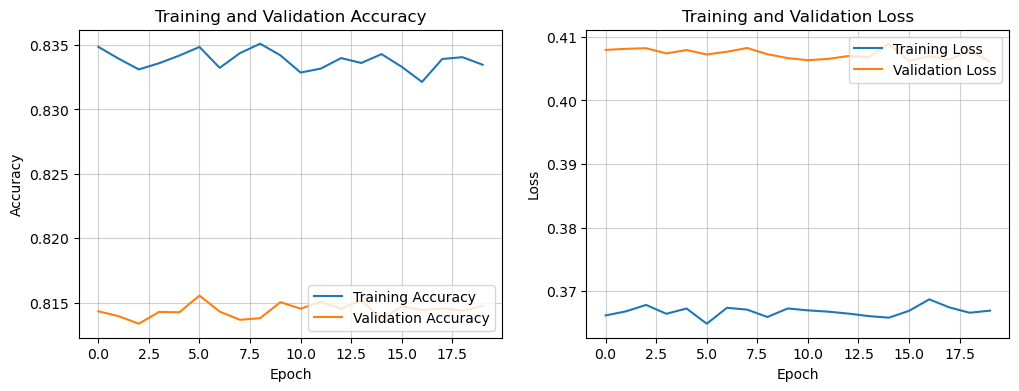

In [13]:
def plot_training_history(history):
    """Plots the training and validation loss and accuracy curves."""
    
    epochs_range = range(len(history['train_acc']))

    plt.figure(figsize=(12, 4))
    
    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_acc'], label='Training Accuracy')
    plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.grid(alpha=0.6)
    plt.legend(loc='lower right')

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history['train_loss'], label='Training Loss')
    plt.plot(epochs_range, history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(alpha=0.6)
    plt.legend(loc='upper right')
    
    plt.show()

plot_training_history(history)


In [22]:
def evaluate_test_set(model, dataloader):
    """Evaluates the model on the test set and returns true/predicted labels and probabilities."""
    model.eval()
    y_true = []
    y_scores = [] # Raw probabilities/scores (output of sigmoid)
    
    print("\nGenerating predictions for Test Set...")
    with torch.no_grad():
        for inputs, labels in tqdm(dataloader, desc="Testing"):
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            outputs = model(inputs)
            
            # Apply sigmoid to get probabilities
            probs = torch.sigmoid(outputs)
            
            y_true.extend(labels.cpu().numpy())
            y_scores.extend(probs.cpu().numpy())
            
    # Convert to NumPy arrays and flatten scores
    y_true = np.array(y_true).astype(int)
    y_scores = np.array(y_scores).flatten()
    
    # Convert scores to binary predictions (0 or 1)
    y_pred_classes = (y_scores > 0.5).astype(int)
    
    return y_true, y_pred_classes, y_scores

y_true, y_pred_classes, y_scores = evaluate_test_set(model, dataloaders['Test'])



Generating predictions for Test Set...


Testing: 100%|██████████████████████████████| 2188/2188 [01:38<00:00, 22.27it/s]


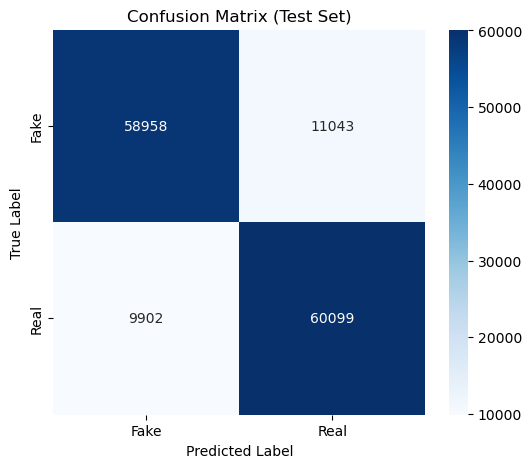

In [23]:
def plot_confusion_matrix(y_true, y_pred_classes, class_labels):
    """Plots the Confusion Matrix."""
    cm = confusion_matrix(y_true, y_pred_classes)
    
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title('Confusion Matrix (Test Set)')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

plot_confusion_matrix(y_true, y_pred_classes, class_names)

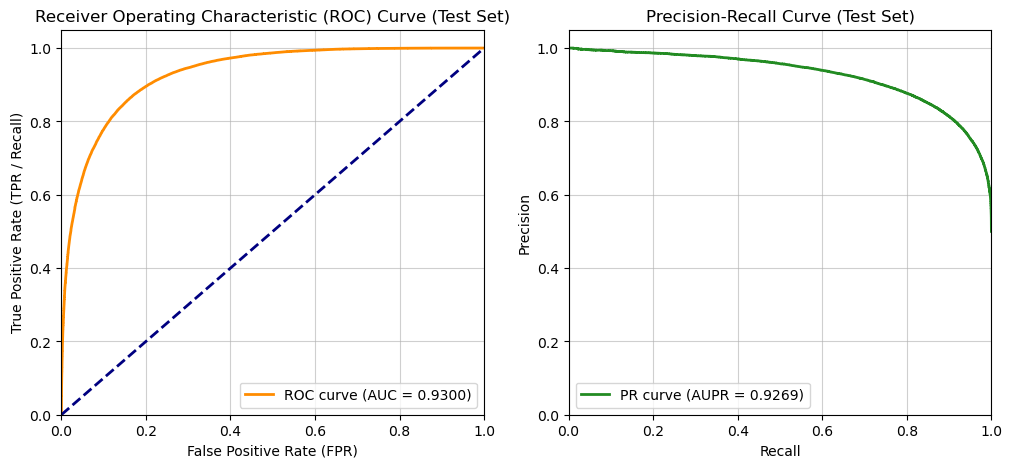


--- Summary of Key Metrics ---
Final Test Accuracy: 85.04%
ROC AUC Score: 0.9300
AUPR Score (Area Under PR Curve): 0.9269


In [24]:
# 1. ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

# 2. Precision-Recall Curve and AUPR
precision, recall, _ = precision_recall_curve(y_true, y_scores)
aupr = average_precision_score(y_true, y_scores)

# --- Plotting ROC and PR Curves ---
plt.figure(figsize=(12, 5))

# Plot ROC Curve
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve (Test Set)')
plt.legend(loc="lower right")
plt.grid(alpha=0.6)

# Plot Precision-Recall Curve
plt.subplot(1, 2, 2)
plt.plot(recall, precision, color='forestgreen', lw=2, label=f'PR curve (AUPR = {aupr:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Test Set)')
plt.legend(loc="lower left")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.grid(alpha=0.6)

plt.show()

# Final Accuracy Calculation
test_accuracy = np.mean(y_true == y_pred_classes)

print("\n--- Summary of Key Metrics ---")
print(f"Final Test Accuracy: {test_accuracy*100:.2f}%")
print(f"ROC AUC Score: {roc_auc:.4f}")
print(f"AUPR Score (Area Under PR Curve): {aupr:.4f}")

In [2]:
!pip install datetime


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [15]:
import datetime
import torch

timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
model_filename = f"deepfake_mobilenet_{timestamp}.pth"
torch.save(model.state_dict(), model_filename)
print(f"\nModel weights saved successfully as: {model_filename}")



Model weights saved successfully as: deepfake_mobilenet_20251110_162136.pth


In [14]:
import torch
import torch.nn as nn
from torchvision import models

device = "cuda" if torch.cuda.is_available() else "cpu"

def build_mobilenet_model():
    model = models.mobilenet_v3_small(weights='IMAGENET1K_V1')
    for param in model.parameters():
        param.requires_grad = False
    num_ftrs = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(num_ftrs, 1)
    return model

model = build_mobilenet_model().to(device)


In [4]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
import os,glob,csv
device = "cuda" if torch.cuda.is_available() else "cpu"
def build_mobilenet_model():
    model = models.mobilenet_v3_small(weights='IMAGENET1K_V1')
    for p in model.parameters():
        p.requires_grad = False
    num_ftrs = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(num_ftrs, 1)
    return model
MODEL_PATHS = glob.glob("*.pth")
MODEL_PATH = MODEL_PATHS[0] if len(MODEL_PATHS)==1 else None
MODEL_PATH


'deepfake_mobilenet_20251110_162136.pth'

In [5]:
if MODEL_PATH is None:
    MODEL_PATH = "deepfake_mobilenet_20251110_184705.pth"
model = build_mobilenet_model().to(device)
state = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(state)
model.eval()
print("Loaded", MODEL_PATH, "on", device)


Loaded deepfake_mobilenet_20251110_162136.pth on cuda


Prediction: Fake   Confidence: 63.26%


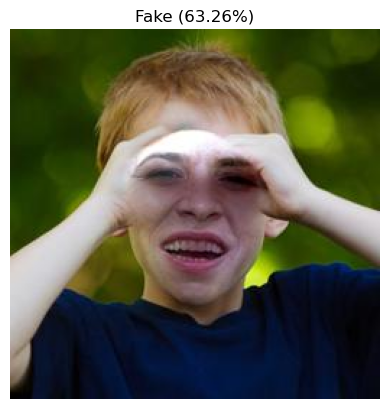

In [9]:
IMAGE_PATH = "fake_365.jpg"
IMAGE_SIZE = 224
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])
img = Image.open(IMAGE_PATH).convert("RGB")
inp = transform(img).unsqueeze(0).to(device)
with torch.no_grad():
    logits = model(inp)
    prob = torch.sigmoid(logits).item()
pred_idx = 1 if prob>0.5 else 0
classes = ['Fake','Real']
pred_label = classes[pred_idx]
confidence = prob if pred_idx==1 else 1-prob
print(f"Prediction: {pred_label}   Confidence: {confidence*100:.2f}%")
plt.imshow(img)
plt.title(f"{pred_label} ({confidence*100:.2f}%)")
plt.axis("off")
plt.show()
